## KMA/MSM 2026/2027 - Úloha 2

### Téma: Testy o poloze — jednovýběrové, dvouvýběrové a vícevýběrové testy, ANOVA, vícerozměrné testy

#### Zvolený dataset: Body performance Data (https://www.kaggle.com/datasets/kukuroo3/body-performance-data/data)

In [15]:
import pandas as pd
df = pd.read_csv('bodyPerformance.csv')
df.head()

,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B


In [ ]:
variables = ['height_cm', 'weight_kg', 'body fat_%']

group_a = df[df['class'] == 'A']
group_b = df[df['class'] == 'B']
group_c = df[df['class'] == 'C']
group_d = df[df['class'] == 'D']


df = df[variables]
df.head()

,height_cm,weight_kg,body fat_%
0,172.3,75.24,21.3
1,165.0,55.80,15.7
2,179.6,78.00,20.1
3,174.5,71.10,18.4
4,173.8,67.70,17.1


 VÝSLEDKY SHAPIRO-WILKOVA TESTU NORMALITY (Skupina A)

Proměnná: height_cm
  - Testová statistika (W): 0.9947
  - p-hodnota: 1.0976e-09
  - Závěr: Zamítáme H0 -> Data NEMAJÍ normální rozdělení.

Proměnná: weight_kg
  - Testová statistika (W): 0.9870
  - p-hodnota: 5.3963e-17
  - Závěr: Zamítáme H0 -> Data NEMAJÍ normální rozdělení.

Proměnná: body fat_%
  - Testová statistika (W): 0.9837
  - p-hodnota: 3.2872e-19
  - Závěr: Zamítáme H0 -> Data NEMAJÍ normální rozdělení.


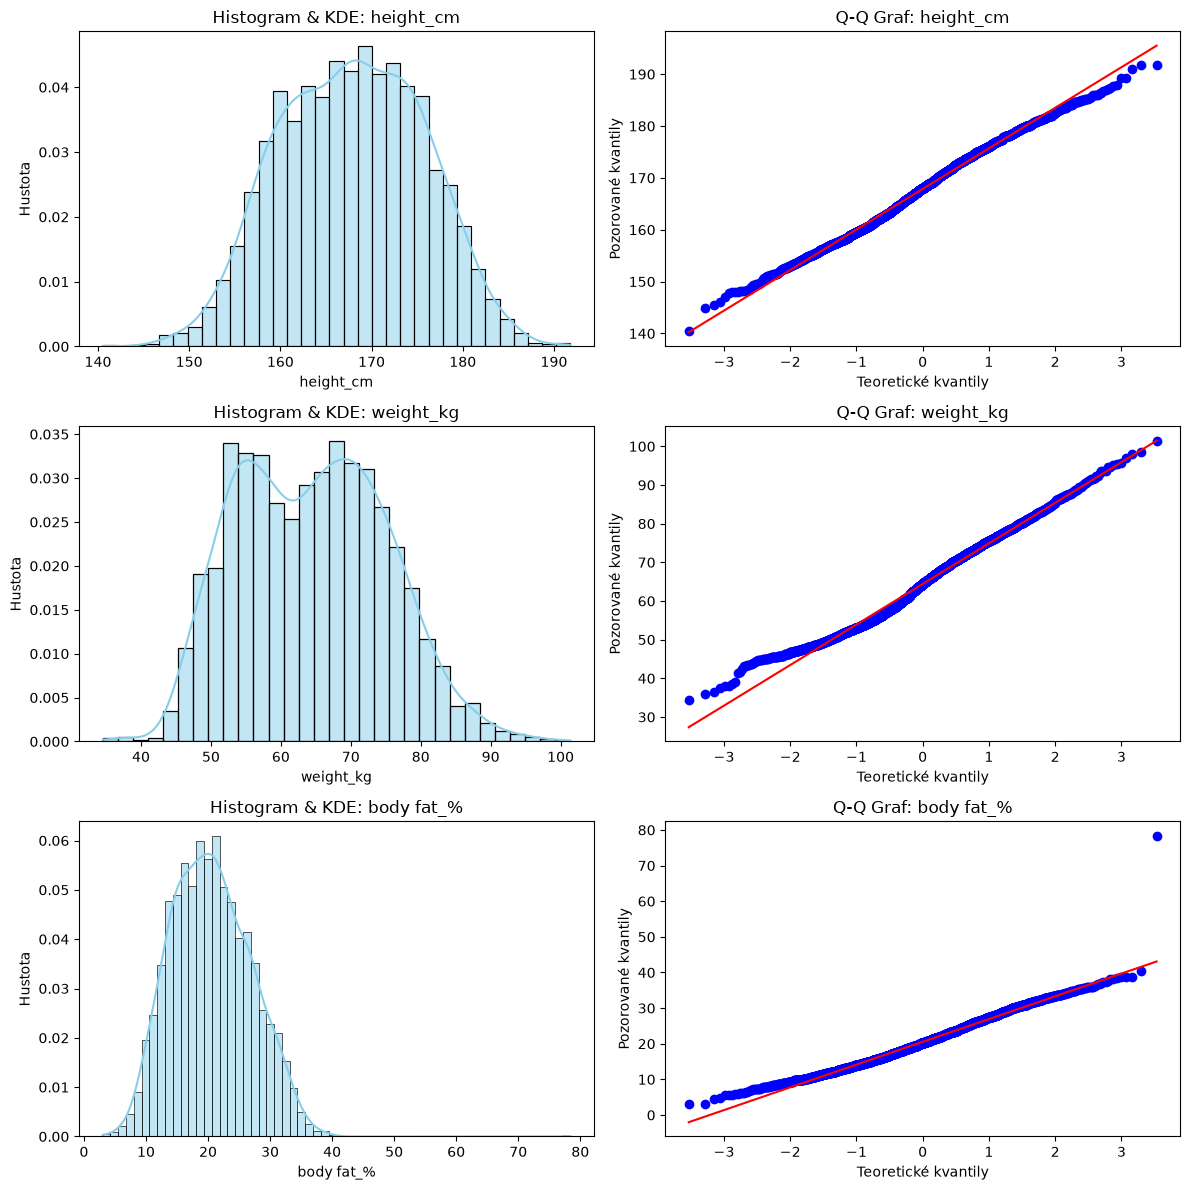

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("SHAPIRO-WILK TEST NORMALITY (Skupina A)")

for var in variables:
    # Shapiro-Wilk test (pro velké soubory dat se často bere náhodný výběr N <= 5000)
    data_sample = group_a[var].dropna()
    if len(data_sample) > 5000:
        data_sample = data_sample.sample(n=5000, random_state=42)
        
    stat, p_val = stats.shapiro(data_sample)
    
    print(f"\nProměnná: {var}")
    print(f"  - Testová statistika (W): {stat:.4f}")
    print(f"  - p-hodnota: {p_val:.4e}")
    
    if p_val > 0.05:
        print("  - Závěr: Nezamykáme H0 -> Data MEMAJÍ statisticky významnou odchylku od normality (jsou normální).")
    else:
        print("  - Závěr: Zamítáme H0 -> Data NEMAJÍ normální rozdělení.")

# 3. Vizualizace: Q-Q grafy a Histogramy
fig, axes = plt.subplots(len(variables), 2, figsize=(12, 4 * len(variables)))

for i, var in enumerate(variables):
    data = group_a[var].dropna()
    
    # Histogram s KDE
    sns.histplot(data, kde=True, ax=axes[i, 0], color='skyblue', stat="density")
    axes[i, 0].set_title(f'Histogram & KDE: {var}')
    axes[i, 0].set_xlabel(var)
    axes[i, 0].set_ylabel('Hustota')
    
    # Q-Q Graf
    stats.probplot(data, dist="norm", plot=axes[i, 1])
    axes[i, 1].set_title(f'Q-Q Graf: {var}')
    axes[i, 1].set_xlabel('Teoretické kvantily')
    axes[i, 1].set_ylabel('Pozorované kvantily')

plt.tight_layout()
plt.show()